In [1]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

X_train = pd.read_csv("../data/processed/train/X_train.csv")
X_test = pd.read_csv("../data/processed/test/X_test.csv")

y_train = pd.read_csv("../data/processed/train/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/test/y_test.csv").squeeze("columns")

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1600, 13)
Test: (400, 13)


In [2]:
ordinal_cols = ["Physical_Activity", "Diet_Quality"]
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns.drop(ordinal_cols)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"]
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("cat", categorical_pipeline, cat_cols)
])

In [3]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    "SVC": SVC(
        random_state=42,
        probability=True
    )
}

In [4]:
def evaluate(model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba, multi_class="ovr"),
    }

trained_models = {
    name: Pipeline([("preprocessor", preprocessor), ("model", model)]).fit(X_train, y_train)
    for name, model in models.items()
}

results_df = pd.DataFrame({n: evaluate(m) for n, m in trained_models.items()}).T
display(results_df.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.765,0.765,0.764,0.764,0.913
Random Forest,0.705,0.703,0.704,0.703,0.855
SVC,0.730,0.733,0.730,0.731,0.890


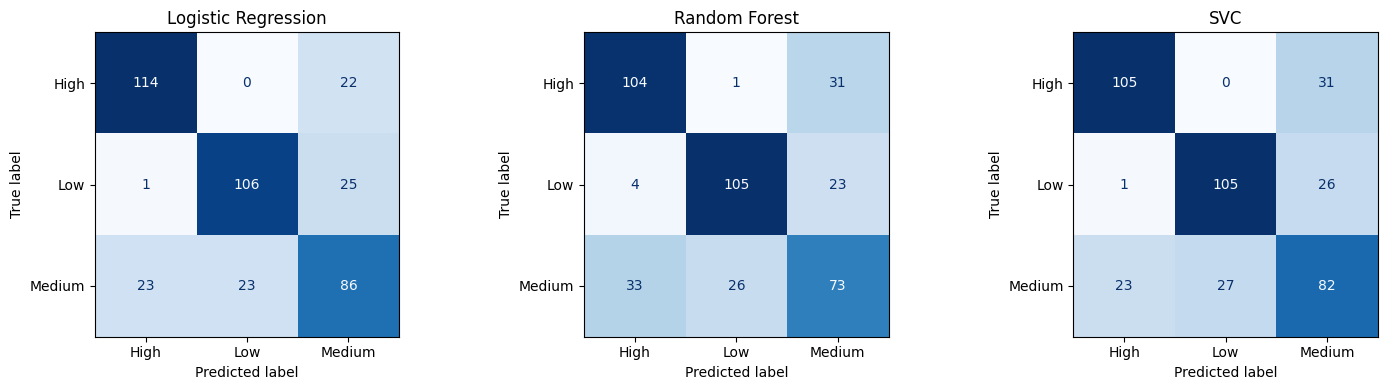

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [6]:

param_grids = {
    "Logistic Regression": {
        "model__C": [3, 10, 30],
        "model__solver": ["lbfgs"],
        "model__class_weight": ["balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [10, None],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
        "model__max_features": ["sqrt"],
        "model__class_weight": ["balanced"]
    },

    "SVC": {
        "model__C": [0.1, 0.5, 1],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale"],
        "model__class_weight": ["balanced"]
    }
}


In [7]:
optimized_models = {}
tuning_results = []

for name, pipeline in trained_models.items():

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1_macro",
        refit=True,
        cv=5,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    optimized_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "CV F1-score": grid.best_score_,
        "Best params": grid.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits


,Model,CV F1-score,Best params
0,Logistic Regression,0.752435,"{'model__C': 30, 'model__class_weight': 'balan..."
1,Random Forest,0.693186,"{'model__class_weight': 'balanced', 'model__ma..."
2,SVC,0.747018,"{'model__C': 0.5, 'model__class_weight': 'bala..."


In [8]:
comparison = tuning_df[["Model", "CV F1-score"]].sort_values(
    "CV F1-score", ascending=False
)
display(comparison.round(3))

best_name = comparison.iloc[0]["Model"]
best_model = optimized_models[best_name]

print("Best model:", best_name)

,Model,CV F1-score
0,Logistic Regression,0.752
2,SVC,0.747
1,Random Forest,0.693


Best model: Logistic Regression


Accuracy     0.765
Precision    0.765
Recall       0.764
F1-score     0.764
ROC-AUC      0.913
dtype: float64

Classification Report:
              precision    recall  f1-score   support

        High       0.83      0.84      0.83       136
         Low       0.82      0.80      0.81       132
      Medium       0.65      0.65      0.65       132

    accuracy                           0.77       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.77      0.77      0.77       400



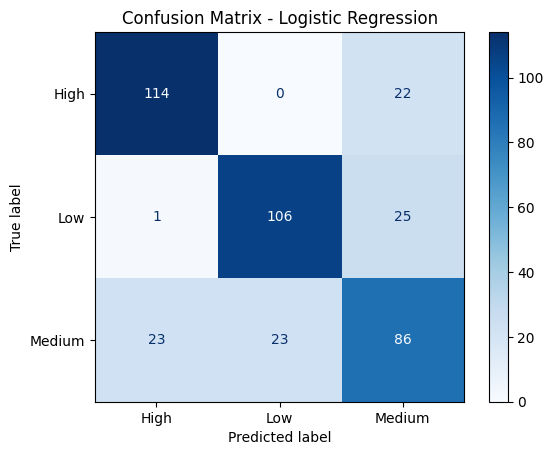

In [9]:
y_pred = best_model.predict(X_test)

final_metrics = evaluate(best_model)
print(pd.Series(final_metrics).round(3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

In [10]:
mask = y_test.values != y_pred

errors = X_test.loc[mask].copy()
errors["Actual"] = y_test[mask].values
errors["Predicted"] = y_pred[mask]

print("Total errors:", len(errors), "out of", len(y_test))
print("\nMost frequent confusions:")
print(errors.groupby(["Actual", "Predicted"]).size().sort_values(ascending=False))

display(errors.head(10))

Total errors: 94 out of 400

Most frequent confusions:
Actual  Predicted
Low     Medium       25
Medium  High         23
        Low          23
High    Medium       22
Low     High          1
dtype: int64


,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Predicted
2,4,5.9,21.7,2.23,6.1,9.0,Moderate,3.1,9.4,86.5,Yes,Poor,No,Low,Medium
3,1,6.9,19.7,2.35,6.4,8.8,Low,6.8,7.2,75.3,Yes,Poor,No,Medium,High
9,1,7.8,4.9,2.15,6.3,9.9,Low,6.1,5.9,78.7,Yes,Good,No,High,Medium
11,3,8.4,18.5,2.47,5.8,8.1,High,3.0,3.4,75.7,No,Poor,No,Medium,Low
12,1,6.1,17.9,2.22,5.5,8.7,High,2.4,7.7,87.9,Yes,Average,No,Medium,Low
17,5,6.5,22.5,2.38,NaN,7.9,High,6.5,8.8,84.7,No,Average,No,Medium,Low
26,5,6.3,25.6,2.60,6.9,8.3,Moderate,4.6,6.2,84.5,No,Good,No,Medium,Low
27,3,6.2,15.1,2.64,8.0,10.5,Low,4.3,4.8,82.1,No,Average,No,Medium,High
38,1,8.3,14.3,2.37,7.2,7.6,Moderate,5.4,NaN,71.2,No,Average,No,Medium,Low
40,2,6.9,19.8,2.49,3.8,6.7,High,2.8,4.5,79.5,No,Average,Yes,Medium,Low


In [11]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(best_model, models_dir / "best_model.joblib")
results_df.to_csv(models_dir / "baseline_results.csv")

json.dump(final_metrics, open(models_dir / "final_metrics.json", "w"))

pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=best_model.classes_),
    index=best_model.classes_, columns=best_model.classes_
).to_csv(models_dir / "confusion_matrix.csv")